# Lab1 Computer Vision
**Ainour Hesham Elshamy** · **23P0111**  
**CSE480/CSE482 — Assignment #01**

This notebook carries out the **four tasks from the supplied lab sheet** with the six provided images. It includes saved processed images, result figures and a small additional image blend using the two cat photos.

### Running in Google Colab
1. Upload this `.ipynb` using **File → Upload notebook**.
2. Open **Runtime → Run all**. If prompted, upload `lab1_images.zip` from the download bundle.
3. See displayed results directly under each task; outputs are also written to the `outputs/` folder.

For local execution, extract the complete project ZIP, open this notebook from the project root and choose **Run All**. The images will already be in `data/`.

In [1]:
from pathlib import Path
import sys, io, zipfile
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
DATA = ROOT / 'data'
OUT = ROOT / 'outputs'
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
required = ['apple.png', 'cameraman.jpg', 'zebra.png', 'marsrover.png', 'blackCat.png', 'whiteCat.png']
missing = [name for name in required if not (DATA / name).exists()]
if missing and 'google.colab' in sys.modules:
    from google.colab import files
    print('Upload lab1_images.zip (recommended), or the six image files individually.')
    uploads = files.upload()
    for filename, raw in uploads.items():
        if filename.lower().endswith('.zip'):
            with zipfile.ZipFile(io.BytesIO(raw)) as archive:
                for entry in archive.infolist():
                    if entry.is_dir():
                        continue
                    basename = Path(entry.filename).name
                    if basename in required:
                        (DATA / basename).write_bytes(archive.read(entry))
        elif Path(filename).name in required:
            (DATA / Path(filename).name).write_bytes(raw)
missing = [name for name in required if not (DATA / name).exists()]
if missing:
    raise FileNotFoundError('Missing images: ' + ', '.join(missing) + '. Put them in data/, or upload lab1_images.zip in Colab.')
print(f'Loaded {len(required)} image files. OpenCV {cv2.__version__}; NumPy {np.__version__}.')

Loaded 6 image files. OpenCV 4.13.0; NumPy 2.3.5.


In [2]:
def load(filename):
    image = cv2.imread(str(DATA / filename), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f'Missing input image: {DATA / filename}')
    return image


def rgb(image):
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def make_panel(filename, tiles, cols=2, figsize=(11, 7.5)):
    rows = int(np.ceil(len(tiles) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax, (title, im, cmap) in zip(axes.flat, tiles):
        ax.imshow(im, cmap=cmap, vmin=0 if cmap == 'gray' else None, vmax=255 if cmap == 'gray' else None)
        ax.set_title(title, fontsize=12, fontweight='semibold')
        ax.axis('off')
    for ax in axes.flat[len(tiles):]:
        ax.axis('off')
    fig.tight_layout(pad=1.4)
    fig.savefig(OUT / filename, dpi=175, facecolor='white', bbox_inches='tight')
    display(fig)
    plt.close(fig)




## Task 1. Selective Colour Isolation
Convert apple image to grayscale; identify dominant red pixels; use binary and inverse masks to combine original colour and gray background.

In [3]:
def task1():
    """Keep dominant-red apple pixels in colour, other pixels grayscale."""
    image = load('apple.png')
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray_bgr = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    b, g, r = cv2.split(image)
    # Cast to signed numbers to prevent overflow when comparing differences.
    r16, g16, b16 = (channel.astype(np.int16) for channel in (r, g, b))
    red_mask = np.where(
        (r16 >= 110) & (r16 - g16 >= 25) & (r16 - b16 >= 40),
        255, 0
    ).astype(np.uint8)
    keep_red = cv2.bitwise_and(image, image, mask=red_mask)
    keep_gray = cv2.bitwise_and(gray_bgr, gray_bgr, mask=cv2.bitwise_not(red_mask))
    result = cv2.add(keep_red, keep_gray)
    cv2.imwrite(str(OUT/'task1_red_mask.png'), red_mask)
    cv2.imwrite(str(OUT/'task1_red_isolation.png'), result)
    make_panel('task1_result_figure.png', [
        ('Original apples', rgb(image), None),
        ('Grayscale background', gray, 'gray'),
        ('Binary red-dominance mask', red_mask, 'gray'),
        ('Final: isolated red areas', rgb(result), None),
    ])
    return {'size': image.shape, 'red_pixel_pct': float((red_mask > 0).mean() * 100)}




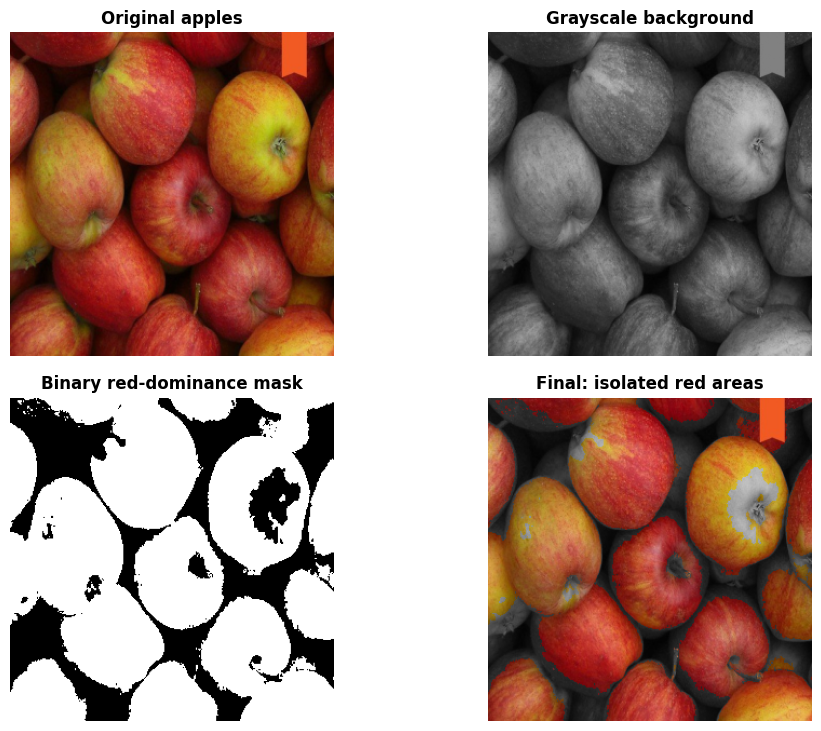

Task 1 completed: {'size': (300, 300, 3), 'red_pixel_pct': 70.1711111111111}


In [4]:
summary1 = task1()
print('Task 1 completed:', summary1)

## Task 2. Creating a Ghostly Overlay
Resize cameraman to zebra dimensions, blend using three opacity settings, and optionally blend both supplied cat photos.

In [5]:
def task2():
    """Blend cameraman and zebra at three weights; extra cat example."""
    zebra = load('zebra.png')
    camera = load('cameraman.jpg')
    height, width = zebra.shape[:2]
    camera_resized = cv2.resize(camera, (width, height), interpolation=cv2.INTER_LINEAR)
    assert camera_resized.shape == zebra.shape
    a25 = cv2.addWeighted(camera_resized, 0.25, zebra, 0.75, 0)
    a50 = cv2.addWeighted(camera_resized, 0.50, zebra, 0.50, 0)
    a75 = cv2.addWeighted(camera_resized, 0.75, zebra, 0.25, 0)
    for value, arr in [('025',a25),('050',a50),('075',a75)]:
        cv2.imwrite(str(OUT / f'task2_ghost_alpha_{value}.png'), arr)
    make_panel('task2_result_figure.png', [
        ('Cameraman resized to zebra', rgb(camera_resized), None),
        ('Zebra base image', rgb(zebra), None),
        ('Cameraman 25% / zebra 75%', rgb(a25), None),
        ('Cameraman 50% / zebra 50%', rgb(a50), None),
        ('Cameraman 75% / zebra 25%', rgb(a75), None),
    ], cols=2, figsize=(10, 11))
    # Both supplied cat images are employed for an optional second overlay.
    cat_black = load('blackCat.png')
    cat_white = load('whiteCat.png')
    cat_overlay = cv2.addWeighted(cat_black, .5, cat_white, .5, 0)
    cv2.imwrite(str(OUT / 'task2_optional_cat_overlay.png'), cat_overlay)
    make_panel('task2_optional_cats_figure.png', [
        ('Black cat', rgb(cat_black), None),
        ('White cat', rgb(cat_white), None),
        ('50% + 50% cat overlay', rgb(cat_overlay), None),
    ], cols=3, figsize=(12.5,4.6))
    return {'aligned_size': zebra.shape, 'alpha_values': [0.25,0.5,0.75]}




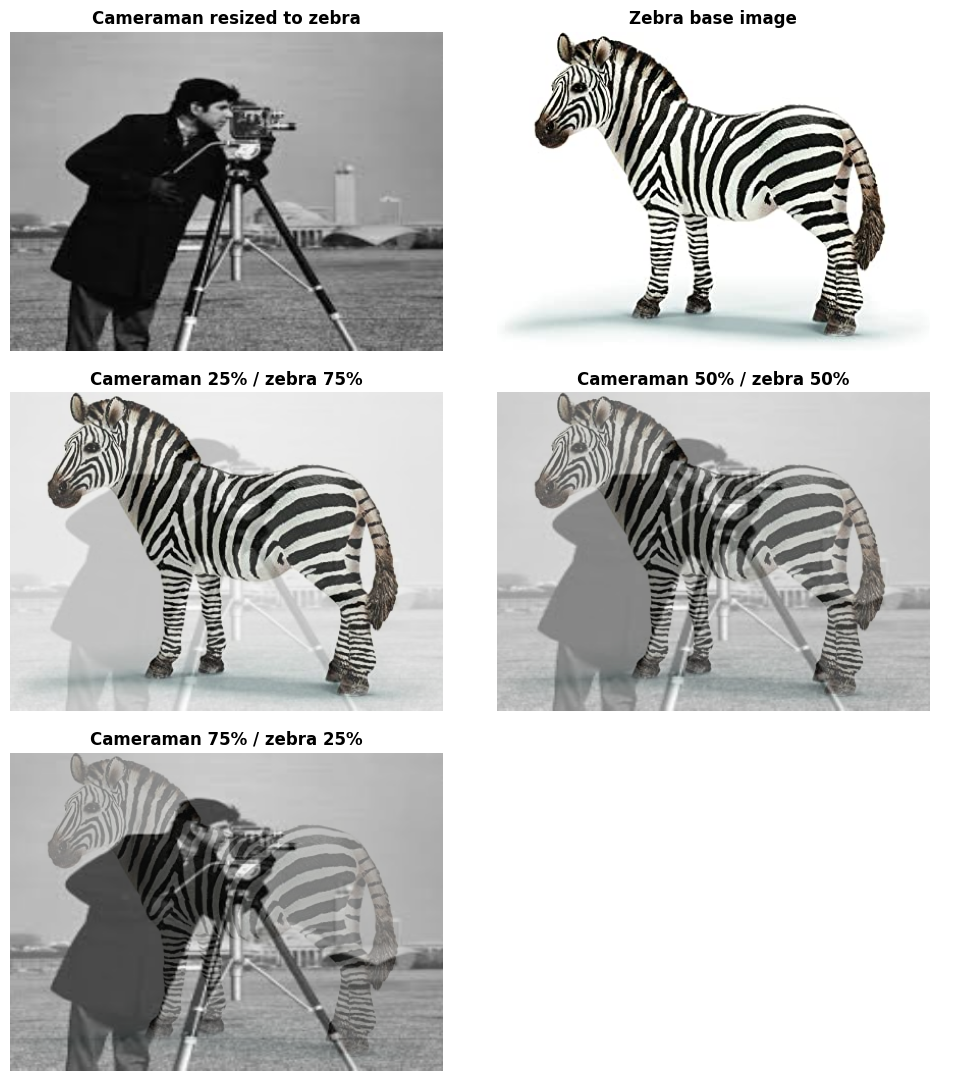

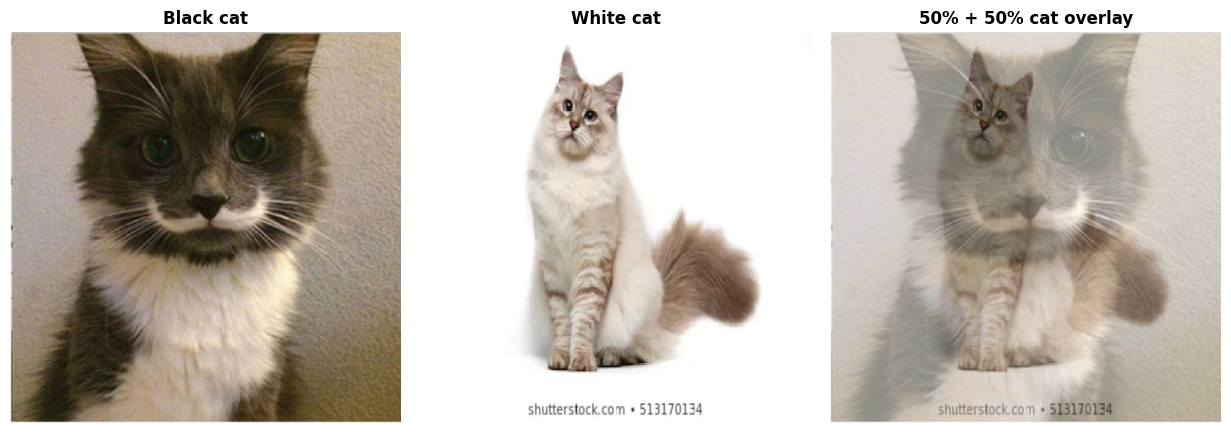

Task 2 completed: {'aligned_size': (313, 425, 3), 'alpha_values': [0.25, 0.5, 0.75]}


In [6]:
summary2 = task2()
print('Task 2 completed:', summary2)

## Task 3. Artistic Vignette Filtering
Draw a white circle on a black mask, Gaussian-blur the mask, and multiply each original pixel by the soft brightness mask.

In [7]:
def task3():
    """Create a blurred circular brightness mask and apply per pixel."""
    image = load('marsrover.png')
    h, w = image.shape[:2]
    circle = np.zeros((h, w), dtype=np.uint8)
    cv2.circle(circle, (w//2, h//2), int(min(h,w)*.53), 255, -1)
    soft = cv2.GaussianBlur(circle, (0,0), sigmaX=65, sigmaY=65)
    mask_float = soft.astype(np.float32) / float(soft.max())
    result = np.clip(image.astype(np.float32) * mask_float[..., None], 0,255).astype(np.uint8)
    cv2.imwrite(str(OUT / 'task3_circle_mask.png'), circle)
    cv2.imwrite(str(OUT / 'task3_soft_mask.png'), soft)
    cv2.imwrite(str(OUT / 'task3_vignette.png'), result)
    make_panel('task3_result_figure.png', [
        ('Original Mars rover', rgb(image), None),
        ('Filled circular mask', circle, 'gray'),
        ('Gaussian-blurred mask', soft, 'gray'),
        ('Final vignette', rgb(result), None),
    ], figsize=(12,7))
    return {'size': image.shape, 'radius_pixels': int(min(h,w)*.53), 'sigma_pixels':65}




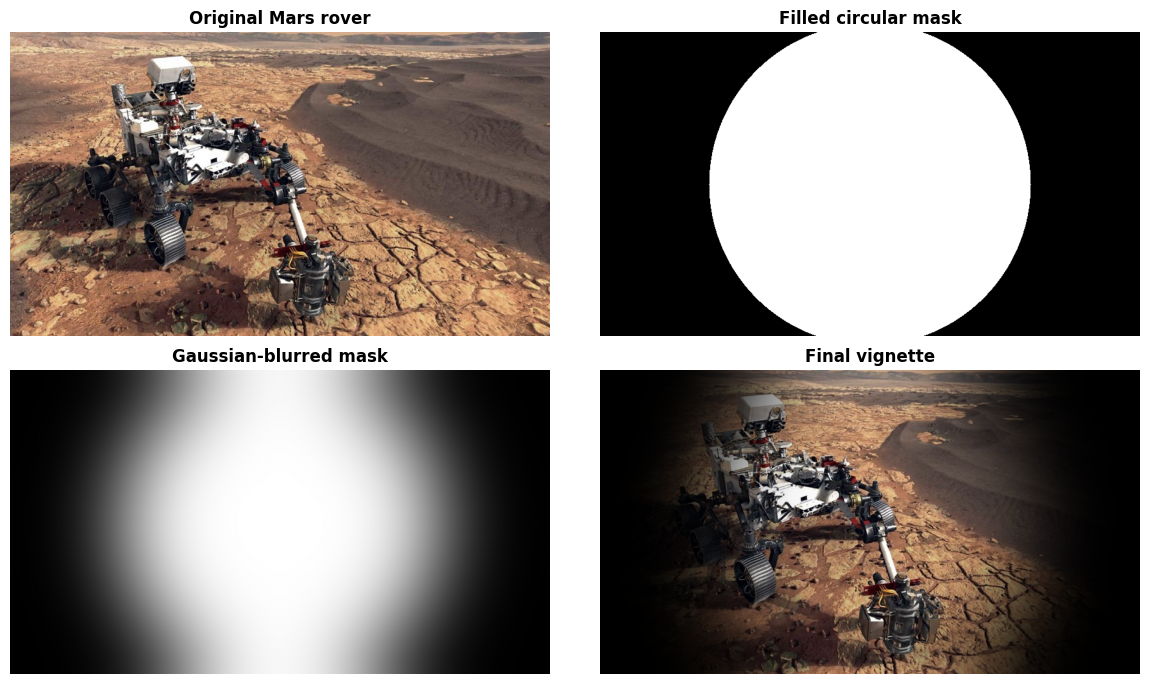

Task 3 completed: {'size': (480, 853, 3), 'radius_pixels': 254, 'sigma_pixels': 65}


In [8]:
summary3 = task3()
print('Task 3 completed:', summary3)

## Task 4. Channel Swapping
Exchange green and red data on the required zebra image. The effect is small because its channels are nearly equal. Repeat on the apples to show a large colour change.

In [9]:
def task4():
    """BGR channel remap: blue output <- blue, green output <- red, red output <- green."""
    zebra = load('zebra.png')
    zb,zg,zr = cv2.split(zebra)
    zebra_swapped = cv2.merge((zb,zr,zg))
    cv2.imwrite(str(OUT / 'task4_zebra_swapped.png'), zebra_swapped)
    apples = load('apple.png')
    ab,ag,ar = cv2.split(apples)
    apple_swapped = cv2.merge((ab,ar,ag))
    cv2.imwrite(str(OUT / 'task4_apple_swapped_demo.png'), apple_swapped)
    make_panel('task4_result_figure.png', [
        ('Original zebra (near grayscale)', rgb(zebra), None),
        ('Zebra: G and R exchanged', rgb(zebra_swapped), None),
        ('Original apples (extra example)', rgb(apples), None),
        ('Apples: G and R exchanged', rgb(apple_swapped), None),
    ], figsize=(11.5, 8))
    mean_diff = np.mean(np.abs(zebra.astype(np.int16)-zebra_swapped.astype(np.int16)))
    return {'mean_abs_zebra_change': float(mean_diff), 'swapped_order': 'B,R,G'}




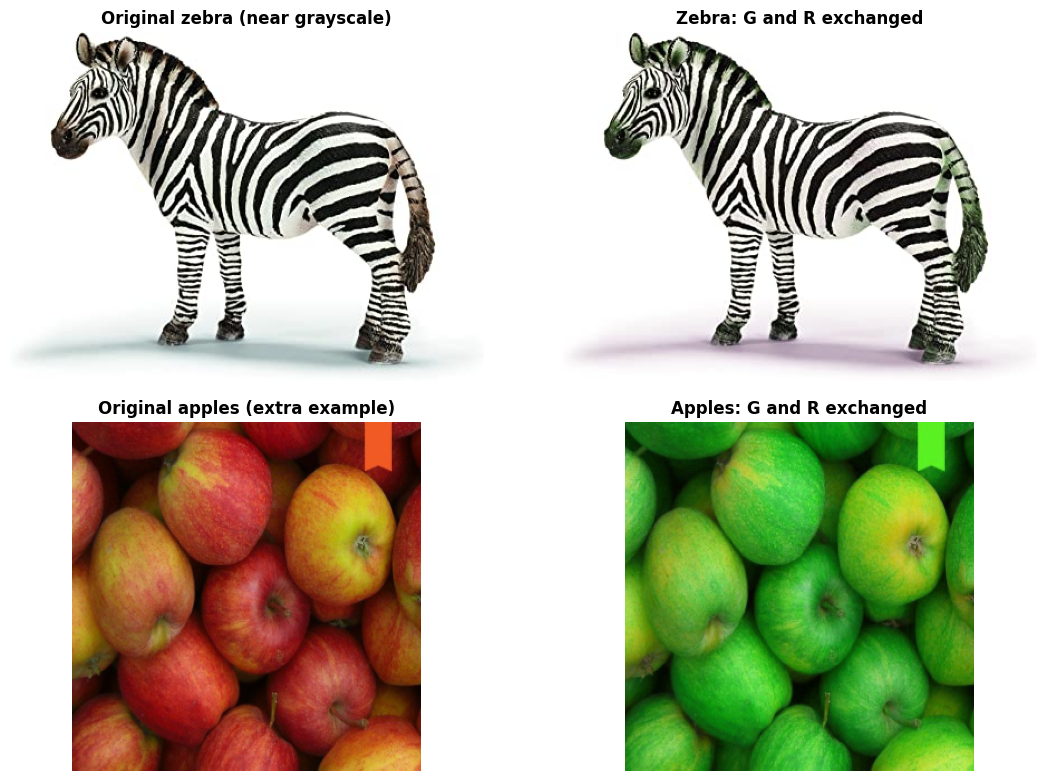

Task 4 completed: {'mean_abs_zebra_change': 1.407920816889056, 'swapped_order': 'B,R,G'}


In [10]:
summary4 = task4()
print('Task 4 completed:', summary4)

## Result and verification notes
- **Task 1:** Red-dominant regions stay in colour; the remaining parts are grayscale. This is a pixel-selection rule, not a perfect object-segmentation model.
- **Task 2:** A small cameraman weight shows more zebra; a larger weight shows more cameraman. The two arrays are resized to exactly the same dimensions.
- **Task 3:** The blurred mask yields smooth edge darkening rather than a hard circular boundary.
- **Task 4:** Swapping nearly equal zebra colour channels has little visible effect; the colourful apples reveal the RGB/BGR remapping more clearly.

**References:** assignment brief supplied with lab; [OpenCV: Changing Colorspaces](https://docs.opencv.org/4.12.0/df/d9d/tutorial_py_colorspaces.html), [OpenCV: Adding/Blending Images](https://docs.opencv.org/4.x/d5/dc4/tutorial_adding_images.html), [OpenCV: Smoothing Images](https://docs.opencv.org/4.x/dc/dd3/tutorial_gausian_median_blur_bilateral_filter.html), [OpenCV: Basic Operations](https://docs.opencv.org/4.x/d3/df2/tutorial_py_basic_ops.html).

In [11]:
print('All four tasks completed successfully.')
print('Figures and processed files available in:', OUT.resolve())
print('Saved files:', len(list(OUT.glob('*.png'))))

All four tasks completed successfully.
Figures and processed files available in: /mnt/data/Lab1_Computer_Vision_23P0111/outputs
Saved files: 16
